# 0. **Contents:**

Section 1 - walkthrough initial setup

Section 2 - finding best HA items

Section 3 - finding best flipping margins

Section 4 - to be planned, will involve utilising price history to look at flip trades



In [ ]:
!pip install OSRSBytes
from OSRSBytes import Items
from scipy.stats import norm
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn as sk
import requests
import scipy
from datetime import datetime as dt


1. a) Set range of items for analysis and set nature rune value for HA profitmaking

In [ ]:
itemspan = 15000

itemlist = []
itemGrab = Items()
natvalue = itemGrab.getBuyAverage('nature rune')

1. b) Create lists that will be stacked into our df

In [ ]:
for k in range(itemspan):
    itemlist.append(itemGrab.getName(str(k)))

#print(itemlist)


GEitems = list(dict.fromkeys(itemlist))

del GEitems[0]

#print(GEitems)
n = len(GEitems)

GEIPB = []                    # buy price
GEIPS = []                    # sell price
GEIPM = []                    # profit margin
GEIPMAP = []                  # profit margin as percentage of average buy/sell price
GEIHA = []                    # high alch val
GEIHAP = []                   # high alch profit if buying item
GEISQ = []                    # sell quantity
GEIBQ = []                    # buy quantity
GEIBL = []                    # buy limit
GEISP = []                    # shop price
GEIHAPNVI = []                # high alch profit if buying items + nature runes

for k in range(n):
    GEIPB.append(itemGrab.getBuyAverage(str(GEitems[k])))
    GEIPS.append(itemGrab.getSellAverage(str(GEitems[k])))
    GEIHA.append(itemGrab.getHighAlchValue(str(GEitems[k])))
    GEISQ.append(itemGrab.getSellQuantity(str(GEitems[k])))
    GEIBQ.append(itemGrab.getBuyQuantity(str(GEitems[k])))
    GEIBL.append(itemGrab.getBuyLimit(str(GEitems[k])))
    GEISP.append(itemGrab.getShopPrice(str(GEitems[k])))
    GEIHAP.append(GEIHA[k] - GEIPB[k])
    GEIHAPNVI.append(GEIHAP[k] - natvalue)
    GEIPM.append(GEIPS[k] - GEIPB[k])
 #   GEIPMAP.append( GEIPM[k]/((GEIPB[k]+GEIPS[k])/2) )

KeyError: ignored

1. c) Create the dataframe

In [ ]:
completeGEIdf = pd.DataFrame(np.column_stack([GEitems, GEIPB, GEIPS, GEIPM, GEIHA, GEIHAP, GEIHAPNVI, GEISQ, GEIBQ, GEIBL, GEISP]),
                             columns = ['Item name', 'GE Item Buy Price', 'GE Item Sell Price', 'Profit Margin', 'GE Item HA Val.', 'GE Item HA Prof.', 'GE HA Prof. BN', 'GE Item Sell Quantity', 'GE Item Buy Quantity',  'GE Item Buy Limit', 'GE Item Shop Price'])

print(completeGEIdf)


completeGEIdf = completeGEIdf[(completeGEIdf['GE Item Buy Price'] != 0) & (completeGEIdf['GE Item Sell Price'] != 0)]


# 2. PART 2A - Finding the best items to High Alch

In [ ]:


HPI = pd.DataFrame(completeGEIdf['GE HA Prof. BN'].astype(str).astype(float).nlargest(50),       # Here we establish the n best items we want to observe that may be good to high alch
                             columns = ['GE HA Prof. BN']                                                  # Although, note that we will have to modify the profit due to the buy limits
)                                                                                                          # An item may have a good GEHAPNVI, but multiply this by its buy limit and divide by limit duration in hours to find prof/hr

HPI = HPI[(HPI['GE HA Prof. BN'] > 0)]


goodHA_IDs = list(HPI.index)           # Creates list of indices that our 'good' alch items are located in

##### Remember what we just mentioned about the buy limits? We need to thus create a df, goodHAdf, that includes buy limit that refreshes every 4 hours
##### Then we multiply the GEIHAPNVI by the buy limit, and divide by 4hrs
##### HOWEVER, the Buy limits are currently not available

#GEIHAPNVI_hrprofit = []      is what we will use if this is fixed




goodHAdf = completeGEIdf.loc[goodHA_IDs]         # Returns dataframe of items that are good to high alch

print(goodHAdf[['Item name', 'GE Item Buy Price', 'GE HA Prof. BN']])



# 3. Finding good items to flip

In [ ]:
# We begin by finding the largest margins between buy/sell price

FPI = pd.DataFrame(completeGEIdf['Profit Margin'].astype(str).astype(float).nlargest(50),
                   columns = ['Profit Margin']
                   )
FPI = FPI[(FPI['Profit Margin'] > 0)]

goodFP_IDs = list(FPI.index)

goodFPdf = completeGEIdf.loc[goodFP_IDs]

print(goodFPdf[['Item name', 'GE Item Buy Price', 'GE Item Sell Price']])

# 4. More advanced trading methods


We can try to utilise historical price data to generate trading signals.

# 4. a) Fetching price data

This is a little messy using OS official API, we will be querying the osrswiki ge charts

There seems to only be 30 day, 90 day, and 180 day price changes on OS official API, which will not make us money. Until we have a better way to fetch daily price data, this method will suck

We can query the db by using this url type: https://api.weirdgloop.org/exchange/history/osrs/all?compress=true&id=X


replace X with item ID

Then we use requests to pull the json and can begin manipulating the price history data


<Axes: xlabel='Date'>

<Figure size 640x480 with 0 Axes>

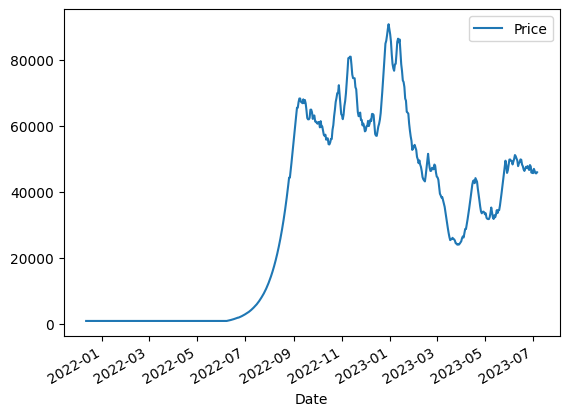

In [ ]:
item_under_test = "kovac's grog"

itemID = itemGrab.getItemID(item_under_test)

url = 'https://api.weirdgloop.org/exchange/history/osrs/all?compress=true&id=' + str(itemID)     ####### Here we are showing how to obtain the price history for the item with ID 1777, AKA the Bow String
                                                                                                 # When we come to replicate this on a larger scale, we can simply create a list of itemIDs and hence a list of urls for multiple item analysis
x = requests.get(url).json()                                                                     # For now, we will look at trading techniques on a single item and monitor performance



undatedItemPriceHist = []
jsdate = []

for i, values in enumerate(list(x[str(itemID)])):
  undatedItemPriceHist.append(int(values[1]))
  jsdate.append(values[0])


def first_10(num):
  return int(str(num)[:10])



d = [first_10(x) for x in jsdate]
date = []
for k in range(len(d)):
  date.append(dt.fromtimestamp(d[k]).strftime('%Y-%m-%d'))

date_dt = [dt.strptime(x,'%Y-%m-%d') for x in date]
priceHistdf = pd.DataFrame(np.column_stack([undatedItemPriceHist, date_dt]),
                           columns = ['Price', 'Date']
)





priceHistdf['Date'] = pd.to_datetime(priceHistdf['Date'])

priceHistdf = priceHistdf.set_index('Date')
plt.figure()
priceHistdf.plot()

4. b) Creating trading strategies

We can begin by introducing basic strategies like SMA

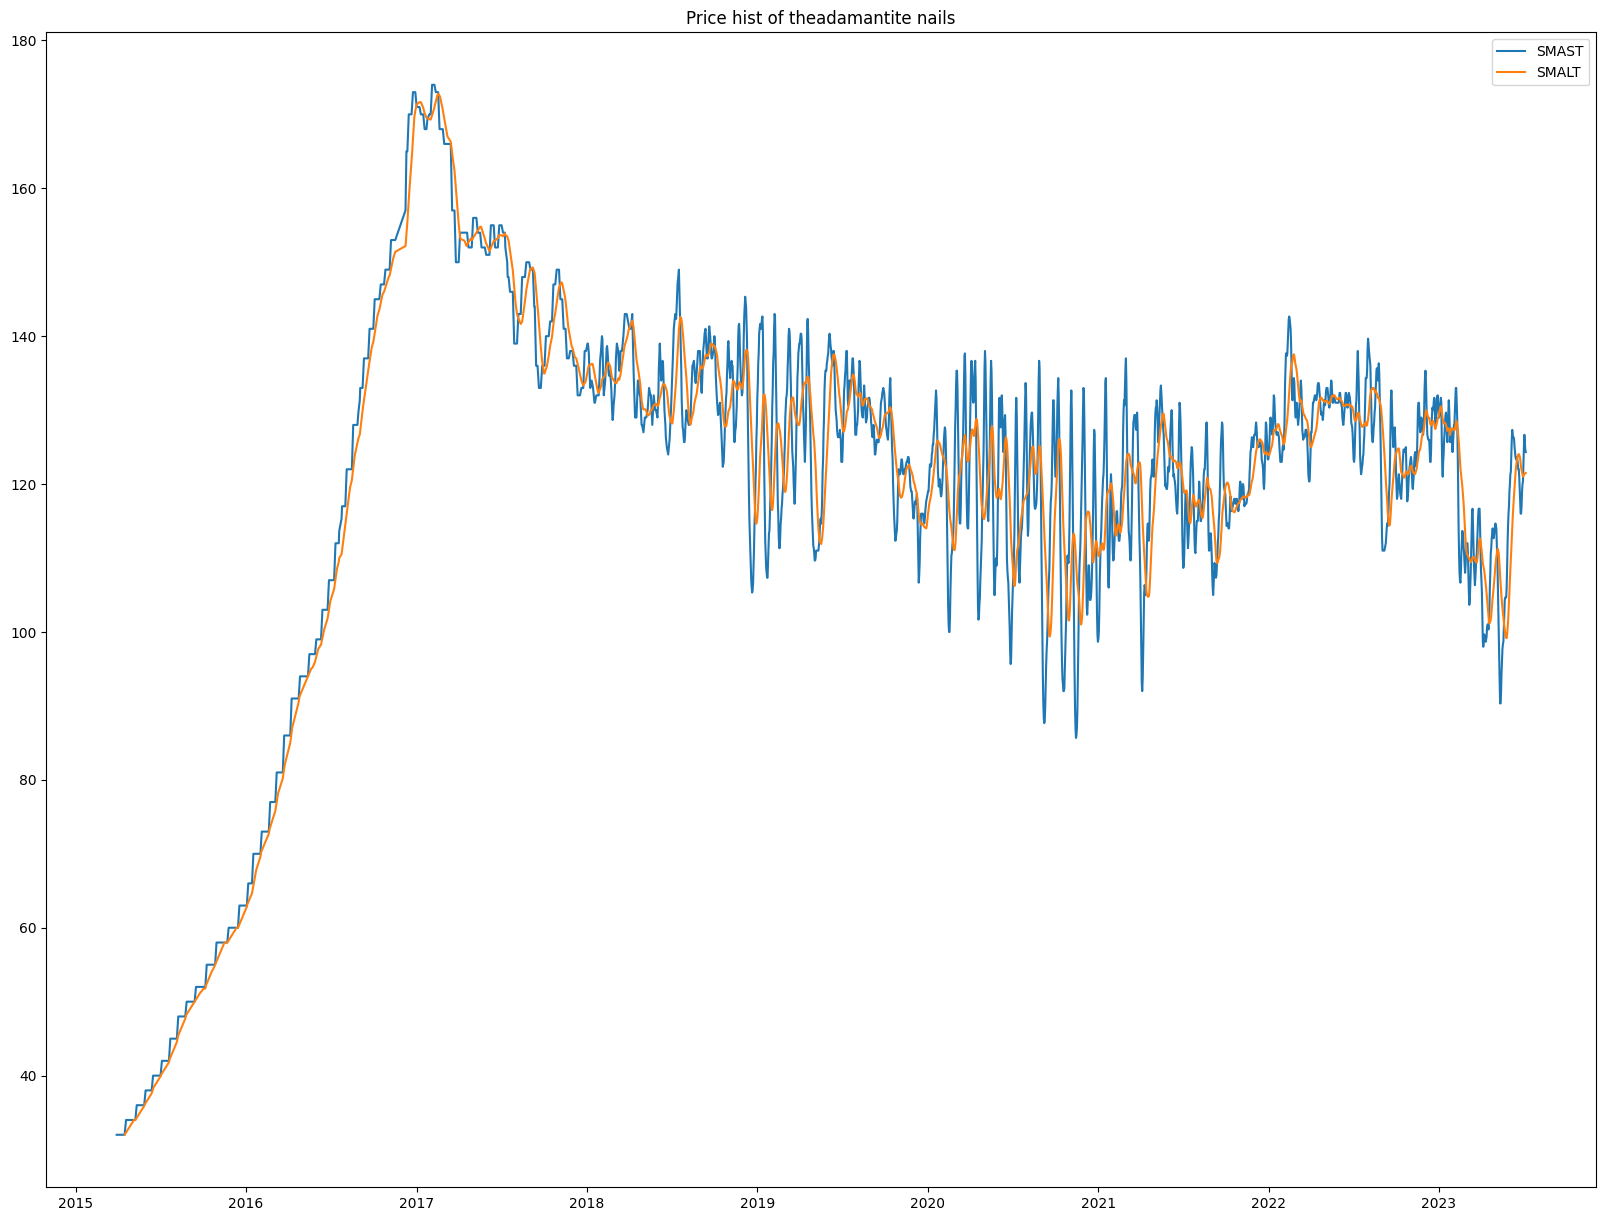

In [ ]:
#calc short and long term moving averages

period_short = 3
period_long = 20


SMAST = pd.DataFrame()
SMAST['Price'] = priceHistdf['Price'].rolling(window=period_short).mean()
SMALT = pd.DataFrame()
SMALT['Price'] = priceHistdf['Price'].rolling(window=period_long).mean()

plt.figure(figsize=(20,15))
#plt.plot(priceHistdf['Price'], label='Price')
plt.plot(SMAST['Price'], label='SMAST')
plt.plot(SMALT['Price'], label='SMALT')
plt.title('Price hist of the' + item_under_test)
plt.legend(loc='upper right')



In [ ]:


def buy_sell(data):
    sigPriceBuy = []
    sigPriceSell = []
    flag = -1

    for i in range(len(data)):
        if data['SMAST'][i] > data['SMALT'][i]:
            if flag != 1:
                sigPriceBuy.append(data['Price'][i])
                sigPriceSell.append(np.nan)
                flag = 1
            else:
                sigPriceBuy.append(np.nan)
                sigPriceSell.append(np.nan)
        elif data['SMAST'][i] < data['SMALT'][i]:
            if flag != 0:
                sigPriceBuy.append(np.nan)
                sigPriceSell.append(data['Price'][i])
                flag = 0

            else:
                sigPriceBuy.append(np.nan)
                sigPriceSell.append(np.nan)

        else:
            sigPriceBuy.append(np.nan)
            sigPriceSell.append(np.nan)

    return (sigPriceBuy, sigPriceSell)


data = pd.DataFrame()
data['Price'] = priceHistdf['Price']
data['SMAST'] = SMAST['Price']
data['SMALT'] = SMALT['Price']

buysell = buy_sell(data)
data['Buy Signal Price'] = buysell[0]
data['Sell Signal Price'] = buysell[1]

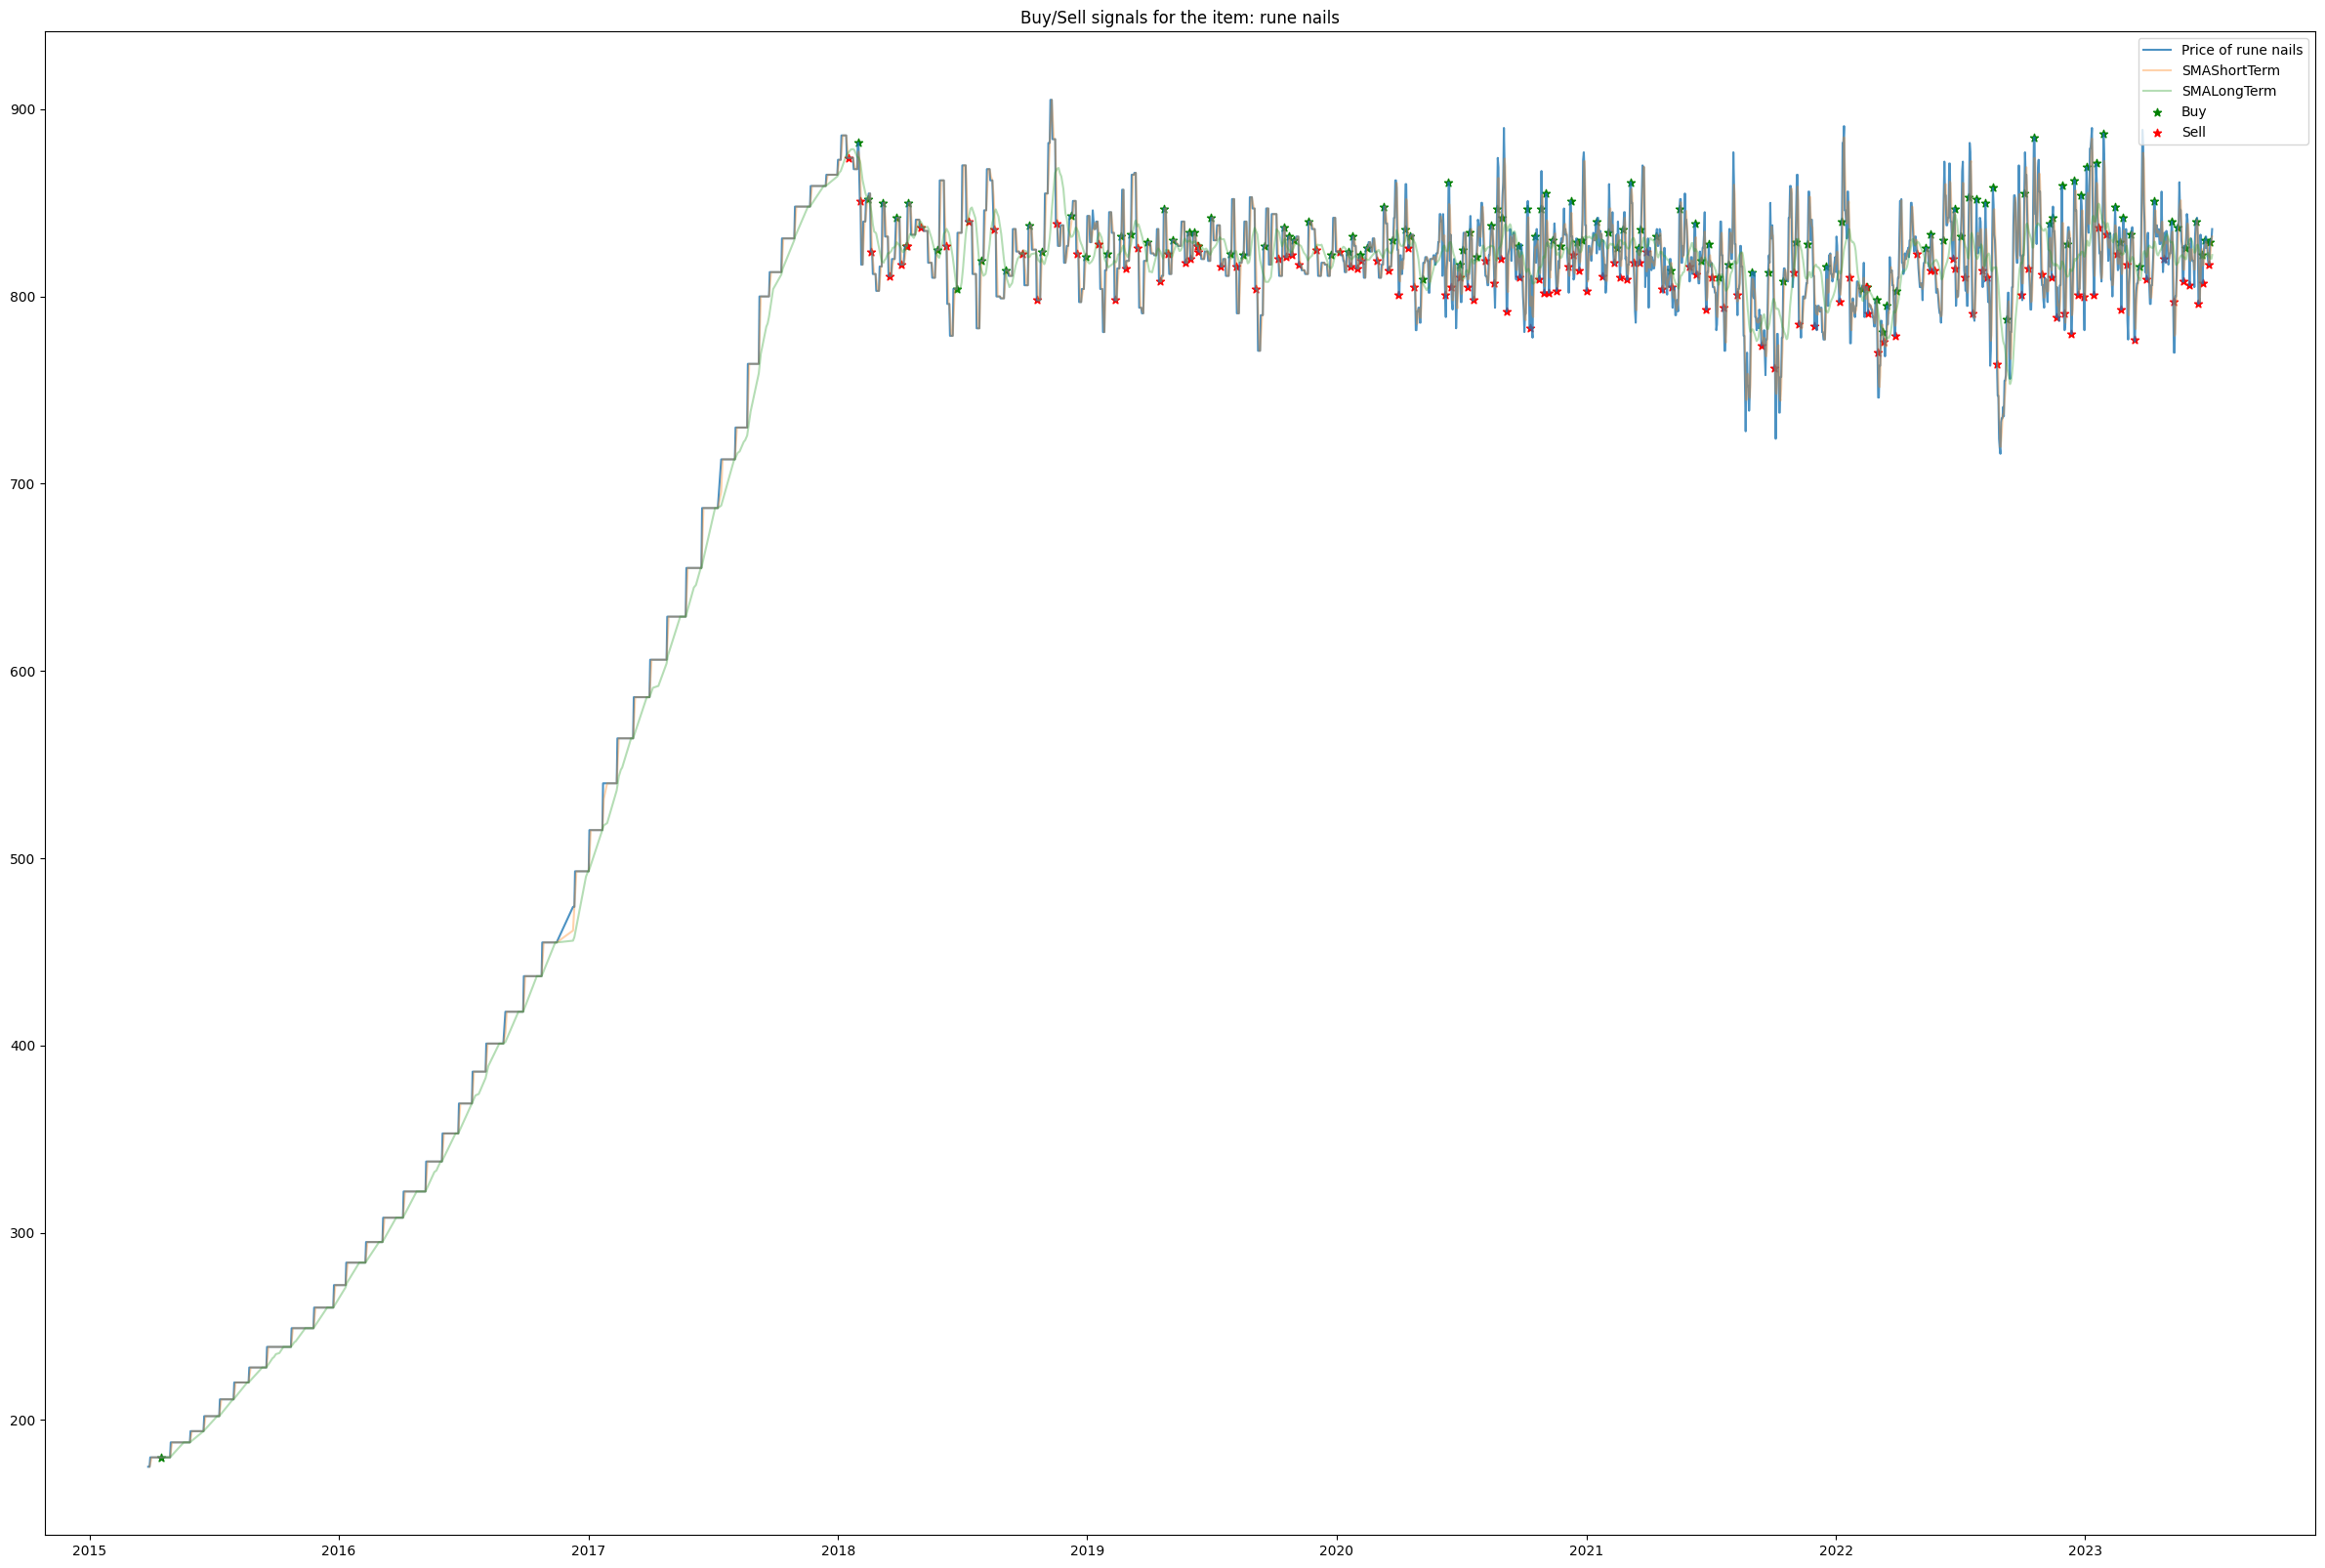

In [ ]:
plt.figure(figsize=(30, 20))


plt.plot(data['Price'], label='Price of ' + item_under_test, alpha=0.8)
plt.plot(SMAST['Price'], label='SMAShortTerm', alpha=0.35)
plt.plot(SMALT['Price'], label='SMALongTerm', alpha=0.35)
plt.scatter(data.index, data['Buy Signal Price'], label='Buy', marker='*', color='green')
plt.scatter(data.index, data['Sell Signal Price'], label='Sell', marker='*', color='red')
plt.title('Buy/Sell signals for the item: ' + item_under_test)
plt.legend(loc='upper right')
plt.show()



In [ ]:
print(data.notna()[::-1].idxmax()['Buy Signal Price'])

lastbuy = data.notna()[::-1].idxmax()['Buy Signal Price']
lastsell = data.notna()[::-1].idxmax()['Sell Signal Price']

if lastbuy < lastsell:
  print('the sell is more recent than the buy - SELL')

else:
  print('the buy is more recent than the sell - BUY')

print('last sell was: ' + str(lastsell))
print('at price: ' + str(data['Price'][lastsell]))
print('last buy was: ' + str(lastbuy))
print('at price: ' + str(data['Price'][lastbuy]))

2023-07-03 00:00:00
the buy is more recent than the sell - BUY
last sell was: 2023-07-01 00:00:00
at price: 817
last buy was: 2023-07-03 00:00:00
at price: 829


# 5. Optimising a "portfolio"

We can essentially craft a portfolio and perform portfolio analysis as a tool to mitigate our risk of loss and maximise return for a given level of risk.

Since we have price history, we can calculate item volatility, mean, and can expand our methods of trading by incorporating techniques more advanced than using simple moving averages.

As an example, we will begin with single asset analysis. This will use the same item_under_test as above in Section 4.



# 5. a) Multi-asset/item analysis



In [ ]:
# We can assume that the periods of daily price history for items from back in 2015 should suffice to represent the returns of certain commodities normally (we stray from rare
# items and armours since on release they have large spikes in value)

# mu represents a vector of returns, mu_bar represents the sample mean, so we begin by assigning these variables

import numpy as np
import pandas as pd
import requests
from datetime import datetime, timedelta

osrs_itemPortfolio_fullHistory = pd.DataFrame()

osrs_itemPortIDS = [10346, 561, 562, 563]
# osrs_itemRef = [3rd age platelegs, ]

for count, n in enumerate(osrs_itemPortIDS):

  url = 'https://api.weirdgloop.org/exchange/history/osrs/all?compress=true&id=' + str(n)
  x = requests.get(url).json()
  print(count)
  # Convert the JSON data into a DataFrame
  temp_df = pd.DataFrame(x[str(n)], columns=['timestamp', 'price', 'volume'])
  temp_df = temp_df.drop(columns=['volume'])  # Drop the 'volume' column
  temp_df['timestamp'] = pd.to_datetime(temp_df['timestamp'], unit='ms')  # Convert the timestamp to a datetime
  print(temp_df['timestamp'].dtype)  # Print the datatype of 'timestamp' after conversion
  temp_df['item_id'] = n   # add a column for item id
  osrs_itemPortfolio_fullHistory = osrs_itemPortfolio_fullHistory.append(temp_df)


print("contents of osrs itemportfolio:")
print(osrs_itemPortfolio_fullHistory)

# Get the current date
now = datetime.now()

# Filter the DataFrame to only include rows within the last 30, 60, or 90 days
osrs_itemPortfolio_30d = osrs_itemPortfolio_fullHistory[osrs_itemPortfolio_fullHistory['timestamp'] > now - timedelta(days=30)]
osrs_itemPortfolio_60d = osrs_itemPortfolio_fullHistory[osrs_itemPortfolio_fullHistory['timestamp'] > now - timedelta(days=60)]
osrs_itemPortfolio_90d = osrs_itemPortfolio_fullHistory[osrs_itemPortfolio_fullHistory['timestamp'] > now - timedelta(days=90)]

# We now have price histories for different periods. We'll investigate all of them, but for now we're going to look at the 90d period.

# Let's find the continuously compounded returns, given by R_t = log( P_t / P_(t-1) )
osrs_itemPortfolio_90d['return'] = np.log(osrs_itemPortfolio_90d.groupby('item_id')['price'].pct_change() + 1)

# Drop any NaN values that may have resulted from the calculation of the log returns
osrs_itemPortfolio_90d = osrs_itemPortfolio_90d.dropna()

# Now, let's calculate the mean return and the covariance matrix for each item in the portfolio
mean_returns = osrs_itemPortfolio_90d.groupby('item_id')['return'].mean()
cov_matrix = osrs_itemPortfolio_90d.pivot(columns='item_id', values='return').cov()

print("Mean Returns:")
print(mean_returns)
print("\nCovariance Matrix:")
print(cov_matrix)


# for count, n in enumerate(osrs_itemPortIDS):
#   url = 'https://api.weirdgloop.org/exchange/history/osrs/all?compress=true&id=' + str(n)
#   x = requests.get(url).json()
#   print(x[str(n)])
#   print('Last 10 entries are')
#   print(x[str(n)][-10:])
#   sub_list = x[str(n)]

#   averages = list(map(scipy.mean, zip(*sub_list)))                                                  #This is going to be the average of the item from the START of the game. We might want more local averages
#                                                                                                      #such as the last 30, 60, 90 or 180 days.



#   id_mean = [str(n), averages[1]]
#   osrs_itemPortfolio_mubar.append(id_mean)


# osrs_PortDF = pd.DataFrame(osrs_itemPortfolio, columns = ['itemID'])

# print(osrs_PortDF)

# portfolio_univar = priceHistdf.agg(['mean', 'count', 'std'])

# print(portfolio_univar)
# # We can plot a confidence interval for the price of the item

# CL = 0.95

# CL_U = (CL + 1)/2
# CL_L = (1 - CL)/2

# CI_u_calc = []
# CI_l_calc = []

# print(portfolio_univar)

# for k in portfolio_univar.index:
#   m, c, s = portfolio_univar.loc[k]
#   CI_u_calc.append(m + norm.ppf(CL_U)*s/math.sqrt(c))

#   CI_l_calc.append(m - norm.ppf(CL_L)*s/math.sqrt(c))

SyntaxError: ignored

Optimising the portfolio

In [ ]:
import cvxpy as cp

# Define the variables
x = cp.Variable(len(osrs_itemPortIDS))

# Define the constraints
constraints = [cp.sum(x) == 1, x >= 0]

# Define the objective function
objective = cp.Maximize(mean_returns.values.T @ x - cp.quad_form(x, cov_matrix.values))

# Define the problem
problem = cp.Problem(objective, constraints)

# Solve the problem
problem.solve()

# Print the optimal portfolio weights
print(x.value)

In [ ]:
# Let's now find appropriate items for the portfolio. Let's get a list of all items, then remove all of the untradeable ones. This narrows our list from 26,000 to 4,000.

import requests

base_url = "https://secure.runescape.com/m=itemdb_oldschool/api/catalogue/items.json?category=1&alpha="
items = []

for letter in 'abcdefghijklmnopqrstuvwxyz':
    url = base_url + letter + "&page=1"
    response = requests.get(url)
    if response.status_code == 200:
        items.extend(response.json().get('items', []))  # Append the 'items' from the response to the list


Here we will allocate a size of capital and try to distribute it based off volatility/expected returns in order to create a risk-hedged portfolio

To do this we have to calculate volatility of in game items (implied vol not possible since there are no options)

In [ ]:
def price_to_int(price_str):
    if isinstance(price_str, int):
        return price_str
    elif 'k' in price_str:
        return int(float(price_str.replace('k', '')) * 1000)
    elif 'm' in price_str:
        return int(float(price_str.replace('m', '')) * 1000000)
    elif 'b' in price_str:
        return int(float(price_str.replace('b', '')) * 1000000000)
    else:
        return int(price_str.replace(',', ''))

filtered_items = []
for item in items:
    price = price_to_int(item['current']['price'])
    if price > 1000000:
        filtered_items.append(item)

print(f"Number of items with price over 1 million: {len(filtered_items)}")


item_names = [item['name'] for item in filtered_items]

for name in item_names:
  print(name)

Number of items with price over 1 million: 31
Abyssal bludgeon
Abyssal dagger
Abyssal dagger (p)
Abyssal dagger (p+)
Abyssal dagger (p++)
Abyssal whip
Accursed sceptre (au)
Accursed sceptre (u)
Dagon'hai robe bottom
Dagon'hai robe top
Dagon'hai robes set
Ghrazi rapier
Ham joint
Imbued heart
Infinity bottoms
Infinity hat
Karil's armour set
Karil's leathertop
Karil's leathertop 0
Mage's book
Magic fang
Necklace of anguish
Ranger boots
Rangers' tunic
Tanzanite fang
Target teleport scroll
Uncharged toxic trident
Uncharged toxic trident (e)
Uncharged trident (e)
Venator bow (uncharged)
Venator shard


In [ ]:
import requests

# Let's check the total number of pages for one of the letters to see if there might be missing pages.
url = "https://secure.runescape.com/m=itemdb_oldschool/api/catalogue/items.json?category=1&alpha=a&page=1"
response = requests.get(url)
print(response.json()['total'])

3964


In [ ]:
import requests
import string
import time
import json

base_url = "https://secure.runescape.com/m=itemdb_oldschool/api/catalogue/items.json?category=1&alpha={}&page={}"

def price_to_int(price_str):
    price_str = str(price_str)
    if 'k' in price_str:
        return int(float(price_str.replace('k', '')) * 1000)
    elif 'm' in price_str:
        return int(float(price_str.replace('m', '')) * 1000000)
    else:
        return int(price_str.replace(',', ''))

desired_count = 10
threshold = 5000000
items = []
found_count = 0

for letter in string.ascii_lowercase[1:]:
    page = 1
    letter_items = []

    while True:
        url = base_url.format(letter, page)

        try:
            response = requests.get(url)
            data = response.json()

            if 'items' in data:
                letter_items += data['items']
                page += 1
            else:
                break
        except json.JSONDecodeError:
            print(f"Failed to parse JSON for URL: {url}")
            break
        except Exception as e:
            print(f"An error occurred for URL: {url}\n{e}")
            break

        time.sleep(1)  # Sleep for 1 second

    # Filter the items for the current letter
    filtered_items = []
    for item in letter_items:
        price = price_to_int(item['current']['price'])
        if price > threshold:
            filtered_items.append(item)

    # Add the filtered items to the overall list
    items += filtered_items
    found_count += len(filtered_items)

    # Check if the desired count has been reached
    if found_count >= desired_count:
        break

# Display the results
print("Number of items with price over", threshold, ":", len(items))
for item in items[:desired_count]:
    print(item['name'])

Failed to parse JSON for URL: https://secure.runescape.com/m=itemdb_oldschool/api/catalogue/items.json?category=1&alpha=b&page=143
Number of items with price over 5000000 : 11
Bandos chestplate
Bandos godsword
Bandos hilt
Bandos tassets
Bandosian components
Basilisk jaw
Blade of saeldor (inactive)
Blood shard
Bow of faerdhinen (inactive)
Bryophyta's essence


In [ ]:
# We can't make enough API calls without being limited, so what we have to do is manually store the recalled information and increment alphabetical starting point as we go on.

# A:
# Abyssal bludgeon
# Abyssal dagger
# Abyssal dagger (p)
# Abyssal dagger (p+)
# Abyssal dagger (p++)
# Abyssal whip
# Accursed sceptre (au)
# Accursed sceptre (u)
# Ahrim's armour set
# Ahrim's robeskirt
# Ahrim's robeskirt 0
# Ahrim's robetop
# Ahrim's robetop 0
# Amulet of eternal glory
# Amulet of fury
# Amulet of torture
# Ancestral hat
# Ancestral robe bottom
# Ancestral robe top
# Ancestral robes set
# Ancient effigy
# Ancient godsword
# Ancient hilt
# Ancient medallion
# Ancient relic
# Ancient statuette
# Ancient wyvern shield
# Anguish ornament kit
# Ankou gloves
# Ankou mask
# Ankou socks
# Ankou top
# Ankou's leggings
# Arcane prayer scroll
# Arcane sigil
# Arcane spirit shield
# Archers ring
# Armadyl chainskirt
# Armadyl chestplate
# Armadyl crossbow
# Armadyl godsword
# Armadyl helmet
# Armadyl hilt
# Armadylean plate
# Avernic defender hilt














#over 5mil:

# Number of items with price over 5000000 : 27
# Abyssal bludgeon
# Ahrim's armour set
# Amulet of eternal glory
# Amulet of torture
# Ancestral hat
# Ancestral robe bottom
# Ancestral robe top
# Ancestral robes set
# Ancient effigy
# Ancient godsword